# Co-learn orbital dynamics and an ensemble filter

Can a position sensor teach us to estimate velocity? In this example we fit both an orbital dynamics model and the filter that assimilates the sensor readings. The only training target is the next noisy position. After training, we can compare the resulting velocity estimates with the simulated truth and an exact Kalman reference.

We adapt auto-differentiable ensemble 3DVar (AD-Ens3DVar) to a short synthetic orbit. Each trainable quantity has a home in Dynestyx. The orbital rate and the process noise belong to the model. The covariance used to assimilate observations belongs to a `SplitFilterConfig` subclass. One call to `dsx.condition` differentiates through both. [Auto-differentiable data assimilation, §§2 and 4.1](https://arxiv.org/html/2603.20891v2)

In [1]:
from dataclasses import dataclass
from time import perf_counter
from typing import NamedTuple

import dynestyx as dsx
import jax
import jax.numpy as jnp
import jax.random as jr
import jax.scipy as jsp
import matplotlib.pyplot as plt
import numpy as np
import optax
from jaxtyping import PRNGKeyArray
from numpyro import distributions as dist

from dynestyx.inference.custom_filter import (
    FilterInputs,
    FilterOutputs,
    PredictedObservationOutputs,
)

## Generate position measurements

Use the six-state Clohessy–Wiltshire equations for relative motion in a rotating frame. If the state is $(x,y,z,v_x,v_y,v_z)$, its acceleration is $(3n^2 x + 2n v_y,-2n v_x,-n^2 z)$, where $n$ is the target's orbital rate. The exact transition over a sampling interval is the matrix exponential of the continuous generator times that interval.

We measure position in km and time in thousands of seconds, so one numerical unit of velocity is 1 m/s. The true rate is 0.0013 radians/s. This tutorial uses shorter trajectories and adds known diagonal process noise to the simulated motion. The true-parameter Kalman filter will then be an exact reference for our synthetic data.

In [2]:
step_size = 0.15  # 150 seconds
times = step_size * jnp.arange(40)
H = jnp.eye(3, 6)
R = 0.1 * jnp.eye(3)
initial_mean = jnp.array([1.0, 0.0, 0.6, 0.0, -1.2, 0.0])
initial_cov = jnp.diag(jnp.array([0.4, 0.4, 0.4, 0.2, 0.2, 0.2]) ** 2)


def orbital_transition(rate):
    coupling = jnp.diag(jnp.array([3.0, 0.0, -1.0])) * rate**2
    rotation = jnp.array([[0.0, 2.0, 0.0], [-2.0, 0.0, 0.0], [0.0, 0.0, 0.0]]) * rate
    generator = jnp.block([[jnp.zeros((3, 3)), jnp.eye(3)], [coupling, rotation]])
    return jsp.linalg.expm(step_size * generator)


class ModelParams(NamedTuple):
    log_rate: jax.Array
    log_process_sd: jax.Array


def make_model(params):
    return dsx.LTI_discrete(
        A=orbital_transition(jnp.exp(params.log_rate)),
        Q=jnp.diag(jnp.exp(2 * params.log_process_sd)),
        H=H,
        R=R,
        initial_mean=initial_mean,
        initial_cov=initial_cov,
    )


true_model_params = ModelParams(
    jnp.log(1.3), jnp.log(jnp.array([0.015] * 3 + [0.03] * 3))
)
true_model = make_model(true_model_params)


def simulate(key):
    init_key, process_key, sensor_key = jr.split(key, 3)
    initial = true_model.initial_condition.sample(init_key)

    def advance(previous, inputs):
        previous_t, current_t, key = inputs
        current = true_model.state_evolution(
            previous, None, previous_t, current_t
        ).sample(key)
        return current, current

    _, tail = jax.lax.scan(
        advance, initial, (times[:-1], times[1:], jr.split(process_key, len(times) - 1))
    )
    states = jnp.concatenate((initial[None], tail))
    positions = jax.vmap(
        lambda state, t, k: true_model.observation_model(state, None, t).sample(k)
    )(states, times, jr.split(sensor_key, len(times)))
    return states, positions


_, train_y = jax.vmap(simulate)(jr.split(jr.key(10), 8))
test_states, test_y = jax.vmap(simulate)(jr.split(jr.key(11), 8))

## Define the analysis on a filter config

Ensemble 3DVar estimates forecast uncertainty in two ways. The sample covariance $\widehat C_t$ responds to the current trajectory, but a small ensemble gives a noisy estimate. The positive semidefinite matrix $BB^\top$ is learned across training trajectories. Their blend supplies the innovation covariance and the gain

$$
C_t=(1-\alpha)BB^\top+\alpha\widehat C_t,\qquad S_t=HC_tH^\top+R,\qquad K_t=C_tH^\top S_t^{-1}.
$$

The ensemble updates use independently perturbed observations. To score the forecast we evaluate the **actual** measurement under $\mathcal N(H\bar x_t^-,S_t)$ before the update. The same innovation factor therefore determines both the observation score and how far each member moves. [AD-Ens3DVar update](https://arxiv.org/html/2603.20891v2#S2.SS1)

In [3]:
class Forecast(NamedTuple):
    members: jax.Array
    cumulative_score: jax.Array


class Analysis(NamedTuple):
    members: jax.Array
    cumulative_score: jax.Array
    prediction: PredictedObservationOutputs
    step_score: jax.Array


def sample_cov(members):
    anomalies = members - members.mean(axis=0)
    return anomalies.T @ anomalies / (len(members) - 1)


@dataclass(frozen=True, kw_only=True)
class Ens3DVarConfig(dsx.configs.SplitFilterConfig[Forecast, Analysis]):
    background_factor: jax.Array
    mixing_logit: jax.Array
    ensemble_size: int = 16

    def initialize(
        self,
        model: dsx.DynamicalModel,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Forecast:
        members = model.initial_condition.sample(key, (self.ensemble_size,))
        return Forecast(members, jnp.zeros(()))

    def predict(
        self,
        model: dsx.DynamicalModel,
        filtered: Analysis,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Forecast:
        def evolve(member, member_key):
            return model.state_evolution(
                member, inputs.u_prev, inputs.time_prev, inputs.time
            ).sample(member_key)

        members = jax.vmap(evolve)(filtered.members, jr.split(key, self.ensemble_size))
        return Forecast(members, filtered.cumulative_score)

    def update(
        self,
        model: dsx.DynamicalModel,
        prior: Forecast,
        inputs: FilterInputs,
        *,
        key: PRNGKeyArray | None,
    ) -> Analysis:
        obs = model.observation_model.params_at(inputs.time)
        H, R = obs.H, obs.R
        alpha = jax.nn.sigmoid(self.mixing_logit)
        background = self.background_factor @ self.background_factor.T
        forecast_cov = (1 - alpha) * background + alpha * sample_cov(prior.members)
        cross = forecast_cov @ H.T
        signal_cov = H @ cross
        innovation_cov = signal_cov + R
        chol = jnp.linalg.cholesky(innovation_cov)
        gain = jsp.linalg.cho_solve((chol, True), cross.T).T
        projected = prior.members @ H.T
        mean = projected.mean(axis=0)
        score = dist.MultivariateNormal(mean, scale_tril=chol).log_prob(inputs.y)
        noisy_y = inputs.y + jr.normal(key, projected.shape) @ jnp.linalg.cholesky(R).T
        updated = prior.members + (noisy_y - projected) @ gain.T
        prediction = PredictedObservationOutputs(
            mean=mean, cov=signal_cov, obs_cov=innovation_cov, noise_cov=R
        )
        return Analysis(updated, prior.cumulative_score + score, prediction, score)

    def gather_outputs(self, prior: Forecast, filtered: Analysis) -> FilterOutputs:
        return FilterOutputs(
            log_normalizing_constant=filtered.cumulative_score,
            filtered_means=filtered.members.mean(axis=0),
            filtered_covariances=sample_cov(filtered.members),
            predicted_observations=filtered.prediction,
            extra_outputs={"step_score": filtered.step_score},
        )

## Learn the dynamics and analysis together

The first observation updates a draw from the initial Gaussian. At subsequent observations Dynestyx calls `predict` and `update` in sequence. We maximize the sum of the resulting forecast log scores using only the eight training measurement sequences. A fixed ensemble key per training sequence keeps the Monte Carlo draws consistent between optimizer steps. We use fresh trajectory and ensemble keys for evaluation.

In [4]:
class AnalysisParams(NamedTuple):
    background_factor: jax.Array
    mixing_logit: jax.Array


initial_params = (
    ModelParams(jnp.log(0.65), jnp.log(0.07 * jnp.ones(6))),
    AnalysisParams(0.25 * jnp.eye(6), jnp.array(-0.8)),
)
train_keys = jr.split(jr.key(20), len(train_y))
test_keys = jr.split(jr.key(21), len(test_y))


def condition_trajectory(params, observations, key):
    dynamics, analysis = params
    config = Ens3DVarConfig(
        background_factor=analysis.background_factor,
        mixing_logit=analysis.mixing_logit,
        crn_seed=key,
    )
    with dsx.Filter(config):
        return dsx.condition(
            "orbit", make_model(dynamics), obs_times=times, obs_values=observations
        )


def loss(params, observations, keys):
    def score(ys, key):
        return condition_trajectory(params, ys, key).marginal_loglik

    return -jax.vmap(score)(observations, keys).mean() / len(times)


value_and_grad = jax.jit(jax.value_and_grad(loss))
initial_loss, gradients = value_and_grad(initial_params, train_y, train_keys)
for name, block in zip(("Model", "Filter"), gradients):
    assert all(bool(jnp.all(jnp.isfinite(leaf))) for leaf in jax.tree.leaves(block))
    norm = float(optax.global_norm(block))
    assert norm > 0
    print(f"{name} gradient norm {norm:.3f}")

# Synchronize one compiled gradient evaluation, excluding compilation and the optimizer.
jax.block_until_ready((initial_loss, gradients))
start = perf_counter()
jax.block_until_ready(value_and_grad(initial_params, train_y, train_keys))
print(
    f"Warm value_and_grad on {jax.devices()[0].platform}: {1e3 * (perf_counter() - start):.1f} ms"
)

Model gradient norm 5.553
Filter gradient norm 44.060
Warm value_and_grad on cpu: 5.3 ms


In [5]:
optimizer = optax.chain(optax.clip_by_global_norm(4.0), optax.adam(0.018))
params = initial_params
opt_state = optimizer.init(params)


@jax.jit
def train_step(params, opt_state, observations, keys):
    value, grads = jax.value_and_grad(loss)(params, observations, keys)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, value


for _ in range(90):
    params, opt_state, _ = train_step(params, opt_state, train_y, train_keys)

trained_loss = float(loss(params, train_y, train_keys))
print(
    f"Training negative log score per time point: {initial_loss:.3f} to {trained_loss:.3f}"
)
for label, (model_params, filter_params) in (
    ("Initial", initial_params),
    ("Trained", params),
):
    rate = float(jnp.exp(model_params.log_rate)) / 1000
    alpha = float(jax.nn.sigmoid(filter_params.mixing_logit))
    print(f"{label:7} orbital rate {rate:.6f} rad/s, ensemble weight {alpha:.2f}")

Training negative log score per time point: 6.836 to 1.198
Initial orbital rate 0.000650 rad/s, ensemble weight 0.31
Trained orbital rate 0.001307 rad/s, ensemble weight 0.37


## Estimate velocity on new trajectories

Compare the initial and trained filters on the same eight held-out trajectories, using a fresh ensemble draw for each pair. For a reference with access to the generating parameters, run Dynestyx's Kalman filter on exactly the same observations. Velocity RMSE pools the three unobserved components, all times and all held-out trajectories. The predictive log score is in nats per three-dimensional observation.

In [6]:
def ensemble_estimate(params, ys, key):
    result = condition_trajectory(params, ys, key)
    return (
        result.states.filtered_means,
        result.marginal_loglik,
        result.extra_outputs["step_score"],
    )


def exact_estimate(ys):
    with dsx.Filter(dsx.configs.KFConfig(filter_source="cuthbert")):
        result = dsx.condition("orbit", true_model, obs_times=times, obs_values=ys)
    return jnp.stack([d.mean for d in result.dists]), result.marginal_loglik


evaluate = jax.jit(jax.vmap(ensemble_estimate, in_axes=(None, 0, 0)))
initial_mean_paths, initial_ll, _ = evaluate(initial_params, test_y, test_keys)
trained_mean_paths, trained_ll, increments = evaluate(params, test_y, test_keys)
kalman_mean_paths, kalman_ll = jax.jit(jax.vmap(exact_estimate))(test_y)
np.testing.assert_allclose(trained_ll, increments.sum(axis=-1), atol=1e-4, rtol=1e-5)

estimates = [
    ("Initialized", initial_mean_paths, initial_ll),
    ("Co-learned", trained_mean_paths, trained_ll),
    ("True-parameter KF", kalman_mean_paths, kalman_ll),
]
print(f"{'Filter':18s}  {'Velocity RMSE (m/s)':>20s}  {'Mean log score (nats)':>22s}")
for label, means, scores in estimates:
    rmse = jnp.sqrt(jnp.mean((means[..., 3:] - test_states[..., 3:]) ** 2))
    print(f"{label:18s}  {rmse:20.3f}  {scores.mean() / len(times):22.3f}")

Filter               Velocity RMSE (m/s)   Mean log score (nats)
Initialized                        2.369                  -8.204
Co-learned                         0.369                  -1.432
True-parameter KF                  0.259                  -1.164


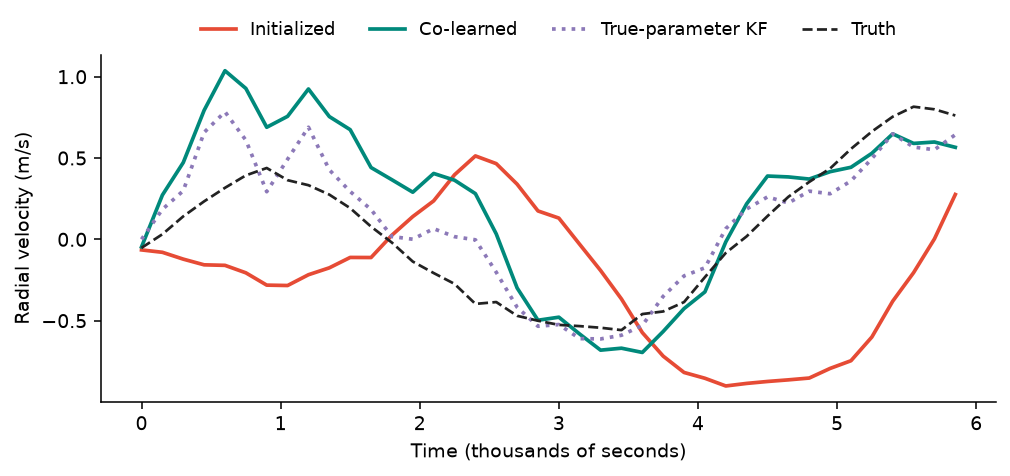

In [7]:
colors = ["#E64B35", "#00897B", "#8C79B8"]
styles = ["-", "-", ":"]
fig, ax = plt.subplots(figsize=(7.4, 3.5), dpi=140)
for (label, means, _), color, style in zip(estimates, colors, styles):
    ax.plot(times, means[0, :, 3], style, lw=1.9, color=color, label=label)
ax.plot(times, test_states[0, :, 3], "--", lw=1.4, color="#222222", label="Truth")
ax.set(xlabel="Time (thousands of seconds)", ylabel="Radial velocity (m/s)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=9
)
fig.tight_layout()
plt.show()

Across the eight held-out trajectories, co-learning reduces velocity RMSE from **2.37 to 0.37 m/s**. The exact KF with the generating parameters reaches 0.26 m/s. On the first trajectory shown above, the initialized filter misses the late rise in radial velocity. The co-learned filter recovers the rise using only the position measurements. Its higher held-out log score also shows that the improvement carries over to predicting the next observation.